# 01 — Berth Allocation with QAOA in Ket

**HYPAQ Ports · Eight-qubit simulator experiment · Apache-2.0**

**Execution:** Ket circuits on CPU KBW, not quantum hardware. Default final
counts are reproducible classical draws through Ket's seeded snapshot sampler
from a KBW-computed state. Training and feedback use analytic simulator
expectations, not shot-estimated measurements. No classical simulator fallback
replaces Ket when an error occurs.

Install the pinned dependencies from the repository root before running:

```bash
python -m pip install -r requirements-quantum.txt
```

For Google Colab, clone the repository and install requirements as described in
`notebooks/quantum/README.md`. Run all cells in order. The quantum add-on must
already be merged into the repository.


## 1. Reuse the original problem and inspect the environment

The classical model, synthetic data and operational validator are reused unchanged. The exact reference establishes the optimum; it does not supply the quantum initial state.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, HTML
from html import escape

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/hypaq_ports/quantum/ket_backend.py").is_file()
             and (p / "data/synthetic/berth_tiny_v1.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Merge the quantum add-on into hypaq-ports first. See notebooks/quantum/README.md for Colab setup.")
sys.path.insert(0, str(ROOT / "src"))
from hypaq_ports.reference import load_json, solve_berth_exact, build_berth_qubo
from hypaq_ports.quantum import run_qaoa, run_falqon
from hypaq_ports.quantum.ket_backend import environment

instance = load_json(ROOT / "data/synthetic/berth_tiny_v1.json")
config = load_json(ROOT / "results/quantum/berth_experiment.json")
print(json.dumps(environment(), indent=2))
print("Instance:", instance["instance_id"])

def show_rows(rows):
    keys = list(rows[0])
    def cell(value):
        if value is None:
            return "—"
        if isinstance(value, float):
            return f"{value:.6g}"
        return escape(str(value))
    header = "".join(f"<th>{escape(k)}</th>" for k in keys)
    body = "".join("<tr>" + "".join(f"<td>{cell(r.get(k))}</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


{
  "python": "3.12.14",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "ket_lang": "0.10.4.2",
  "ket_components": [
    "Ket v0.10.4.2",
    "libket v0.7.1 [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]",
    "kbw v0.5.1 [GPU, CUDA] [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]"
  ],
  "numpy": "2.3.5",
  "scipy": "1.17.0"
}
Instance: berth_tiny_v1


In [2]:
reference = solve_berth_exact(instance)
model = build_berth_qubo(instance)
print("Encoded qubits:", len(model["variables"]))
print("Classical optimal waiting slots:", reference["metrics"]["total_waiting_slots"])
print("Classical schedule:", reference["schedule"])


Encoded qubits: 8
Classical optimal waiting slots: 0
Classical schedule: [{'vessel': 'V1', 'berth': 'B1', 'slot': 0}, {'vessel': 'V2', 'berth': 'B1', 'slot': 1}]


## 2. Execute QAOA

The cost is converted to Ising, its constant omitted only as a global phase, and
its nonconstant coefficients divided by a common scale. Explicit RZ/CNOT gates
implement cost evolution; RX gates implement the transverse-X mixer. The report
restores both scaling and the constant in full energies.

COBYLA uses exact KBW expectations, with two restarts and a fixed evaluation
budget. The first initialization is a documented small-angle schedule; the next
uses seeded random angles. Budget termination is not convergence certification.
The initial state is uniform over all bitstrings, including infeasible ones.

In [3]:
result = run_qaoa(instance, **config["common"], **config["qaoa"])
print("Executed:", result["execution_target"])
print("Parameters:", result["parameters"])
print(json.dumps(result["restart_reports"], indent=2))


Executed: KBW CPU state-vector simulator
Parameters: [0.33239580947682634, 0.8804091225807699, -0.5339768054204562, -0.2602899874135089]
[
  {
    "restart": 0,
    "success": false,
    "message": "Return from COBYLA because the objective function has been evaluated MAXFUN times.",
    "evaluations": 80,
    "returned_normalized_energy": -3.0329143168252886
  },
  {
    "restart": 1,
    "success": false,
    "message": "Return from COBYLA because the objective function has been evaluated MAXFUN times.",
    "evaluations": 80,
    "returned_normalized_energy": -1.0483338864261729
  }
]


## 3. Validate samples and keep energy separate from waiting time

The most frequent bitstring may be infeasible. Feasibility and waiting time come from the original operational validator. No feasible sampled solution is represented by a null cost, never by an invented optimum.

In [4]:
# Check that expectation and readout agree within native simulator precision.
assert abs(result["metrics"]["expected_full_qubo_energy"] -
           result["final_full_energy_from_observable"]) < 0.003
assert sum(result["counts"].values()) == config["common"]["shots"]
print(json.dumps({
    "metrics": {k: v for k, v in result["metrics"].items() if k != "top_sampled_states"},
    "resources": {k: result[k] for k in ["logical_gate_count", "logical_depth",
                  "cost_expectation_queries", "feedback_expectation_queries", "circuit_preparations"]},
    "sampling": result["sampling_description"],
    "elapsed_seconds": result["elapsed_seconds"],
}, indent=2))
show_rows([{k: r[k] for k in ["bits", "count", "probability", "feasible", "waiting_slots", "qubo_energy"]}
           for r in result["metrics"]["top_sampled_states"][:5]])


{
  "metrics": {
    "reference_optimal_waiting_slots": 0,
    "expected_full_qubo_energy": 2.3847984638672823,
    "exact_feasible_probability": 0.23665042085654578,
    "exact_optimal_probability": 0.1721321358839982,
    "conditional_expected_feasible_waiting_slots": 0.2726311862832379,
    "sampled_feasible_rate": 0.231689453125,
    "sampled_optimal_rate": 0.16748046875,
    "best_sampled_feasible_waiting_slots": 0,
    "best_sampled_absolute_gap_slots": 0,
    "best_sampled_feasible_schedule": [
      {
        "vessel": "V1",
        "berth": "B1",
        "slot": 0
      },
      {
        "vessel": "V2",
        "berth": "B2",
        "slot": 1
      }
    ]
  },
  "resources": {
    "logical_gate_count": 136,
    "logical_depth": 50,
    "cost_expectation_queries": 161,
    "feedback_expectation_queries": 0,
    "circuit_preparations": 161
  },
  "sampling": "Ket QuantumState.sample on a KBW state snapshot; classical seeded sampling",
  "elapsed_seconds": 2.7361763549997704
}

bits,count,probability,feasible,waiting_slots,qubo_energy
00000000,486,0.121585,False,—,4
00100000,300,0.067318,False,—,2
00000100,279,0.0642761,False,—,2
10000000,278,0.067318,False,—,2
00000001,267,0.0642761,False,—,2


## 4. Inspect the optimization trajectory

Raw objective evaluations need not decrease. The running minimum shows the best parameters retained so far. Different restarts are included in the evaluation sequence.

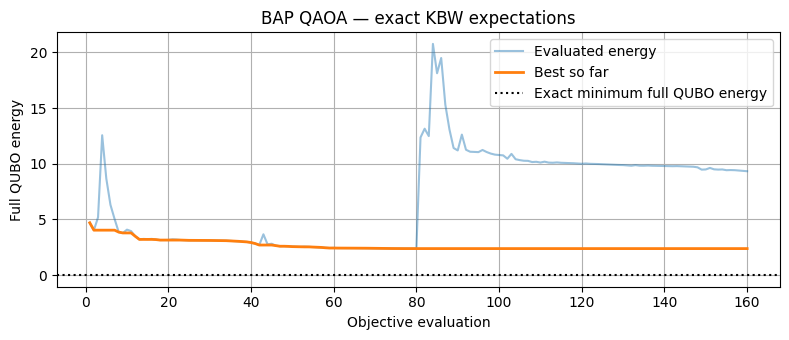

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True})
trace = result["optimization_trace"]
values = [r["full_qubo_energy"] for r in trace]
best = []
for value in values:
    best.append(min(value, best[-1]) if best else value)
plt.plot(range(1, len(values)+1), values, alpha=0.45, label="Evaluated energy")
plt.plot(range(1, len(values)+1), best, linewidth=2, label="Best so far")
plt.axhline(0, color="black", linestyle=":", label="Exact minimum full QUBO energy")
plt.xlabel("Objective evaluation"); plt.ylabel("Full QUBO energy")
plt.title("BAP QAOA — exact KBW expectations"); plt.legend(); plt.tight_layout(); plt.show()


## Explore next

1. Change p and the evaluation budget; record both quality and resources.
2. Repeat over several initialization seeds and instances before drawing conclusions.
3. Set `sampling="kbw_native"` to call Ket's native sampler; its seed is not exposed by this adapter.
4. Inspect infeasible samples and compare energy with operational violations.
5. Add a nonzero-optimum instance while retaining independent classical validation.

A best sampled waiting cost of zero does not mean all samples are feasible or
that QAOA is certified optimal. No speedup is claimed. The current CP-SAT adapter
remains future work.